# K-Nearest Neighbors: Choosing K with the Elbow Method

The dataset has 10 anonymised numeric features and a binary `TARGET CLASS`. Because the feature names are hidden,
the focus is on the **method**: scaling the data, fitting KNN, and choosing the number of neighbours `K`.

**Tools:** pandas, seaborn, scikit-learn (`StandardScaler`, `KNeighborsClassifier`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

## 1. Data

In [2]:
df = pd.read_csv('data/knn_project_data.csv')
df.head()

,XVPM,GWYH,TRAT,TLLZ,IGGA,HYKR,EDFS,GUUB,MGJM,JHZC,TARGET CLASS
0,1636.670614,817.988525,2565.995189,358.347163,550.417491,1618.870897,2147.641254,330.727893,1494.878631,845.136088,0
1,1013.402760,577.587332,2644.141273,280.428203,1161.873391,2084.107872,853.404981,447.157619,1193.032521,861.081809,1
2,1300.035501,820.518697,2025.854469,525.562292,922.206261,2552.355407,818.676686,845.491492,1968.367513,1647.186291,1
3,1059.347542,1066.866418,612.000041,480.827789,419.467495,685.666983,852.867810,341.664784,1154.391368,1450.935357,0
4,1018.340526,1313.679056,950.622661,724.742174,843.065903,1370.554164,905.469453,658.118202,539.459350,1899.850792,0


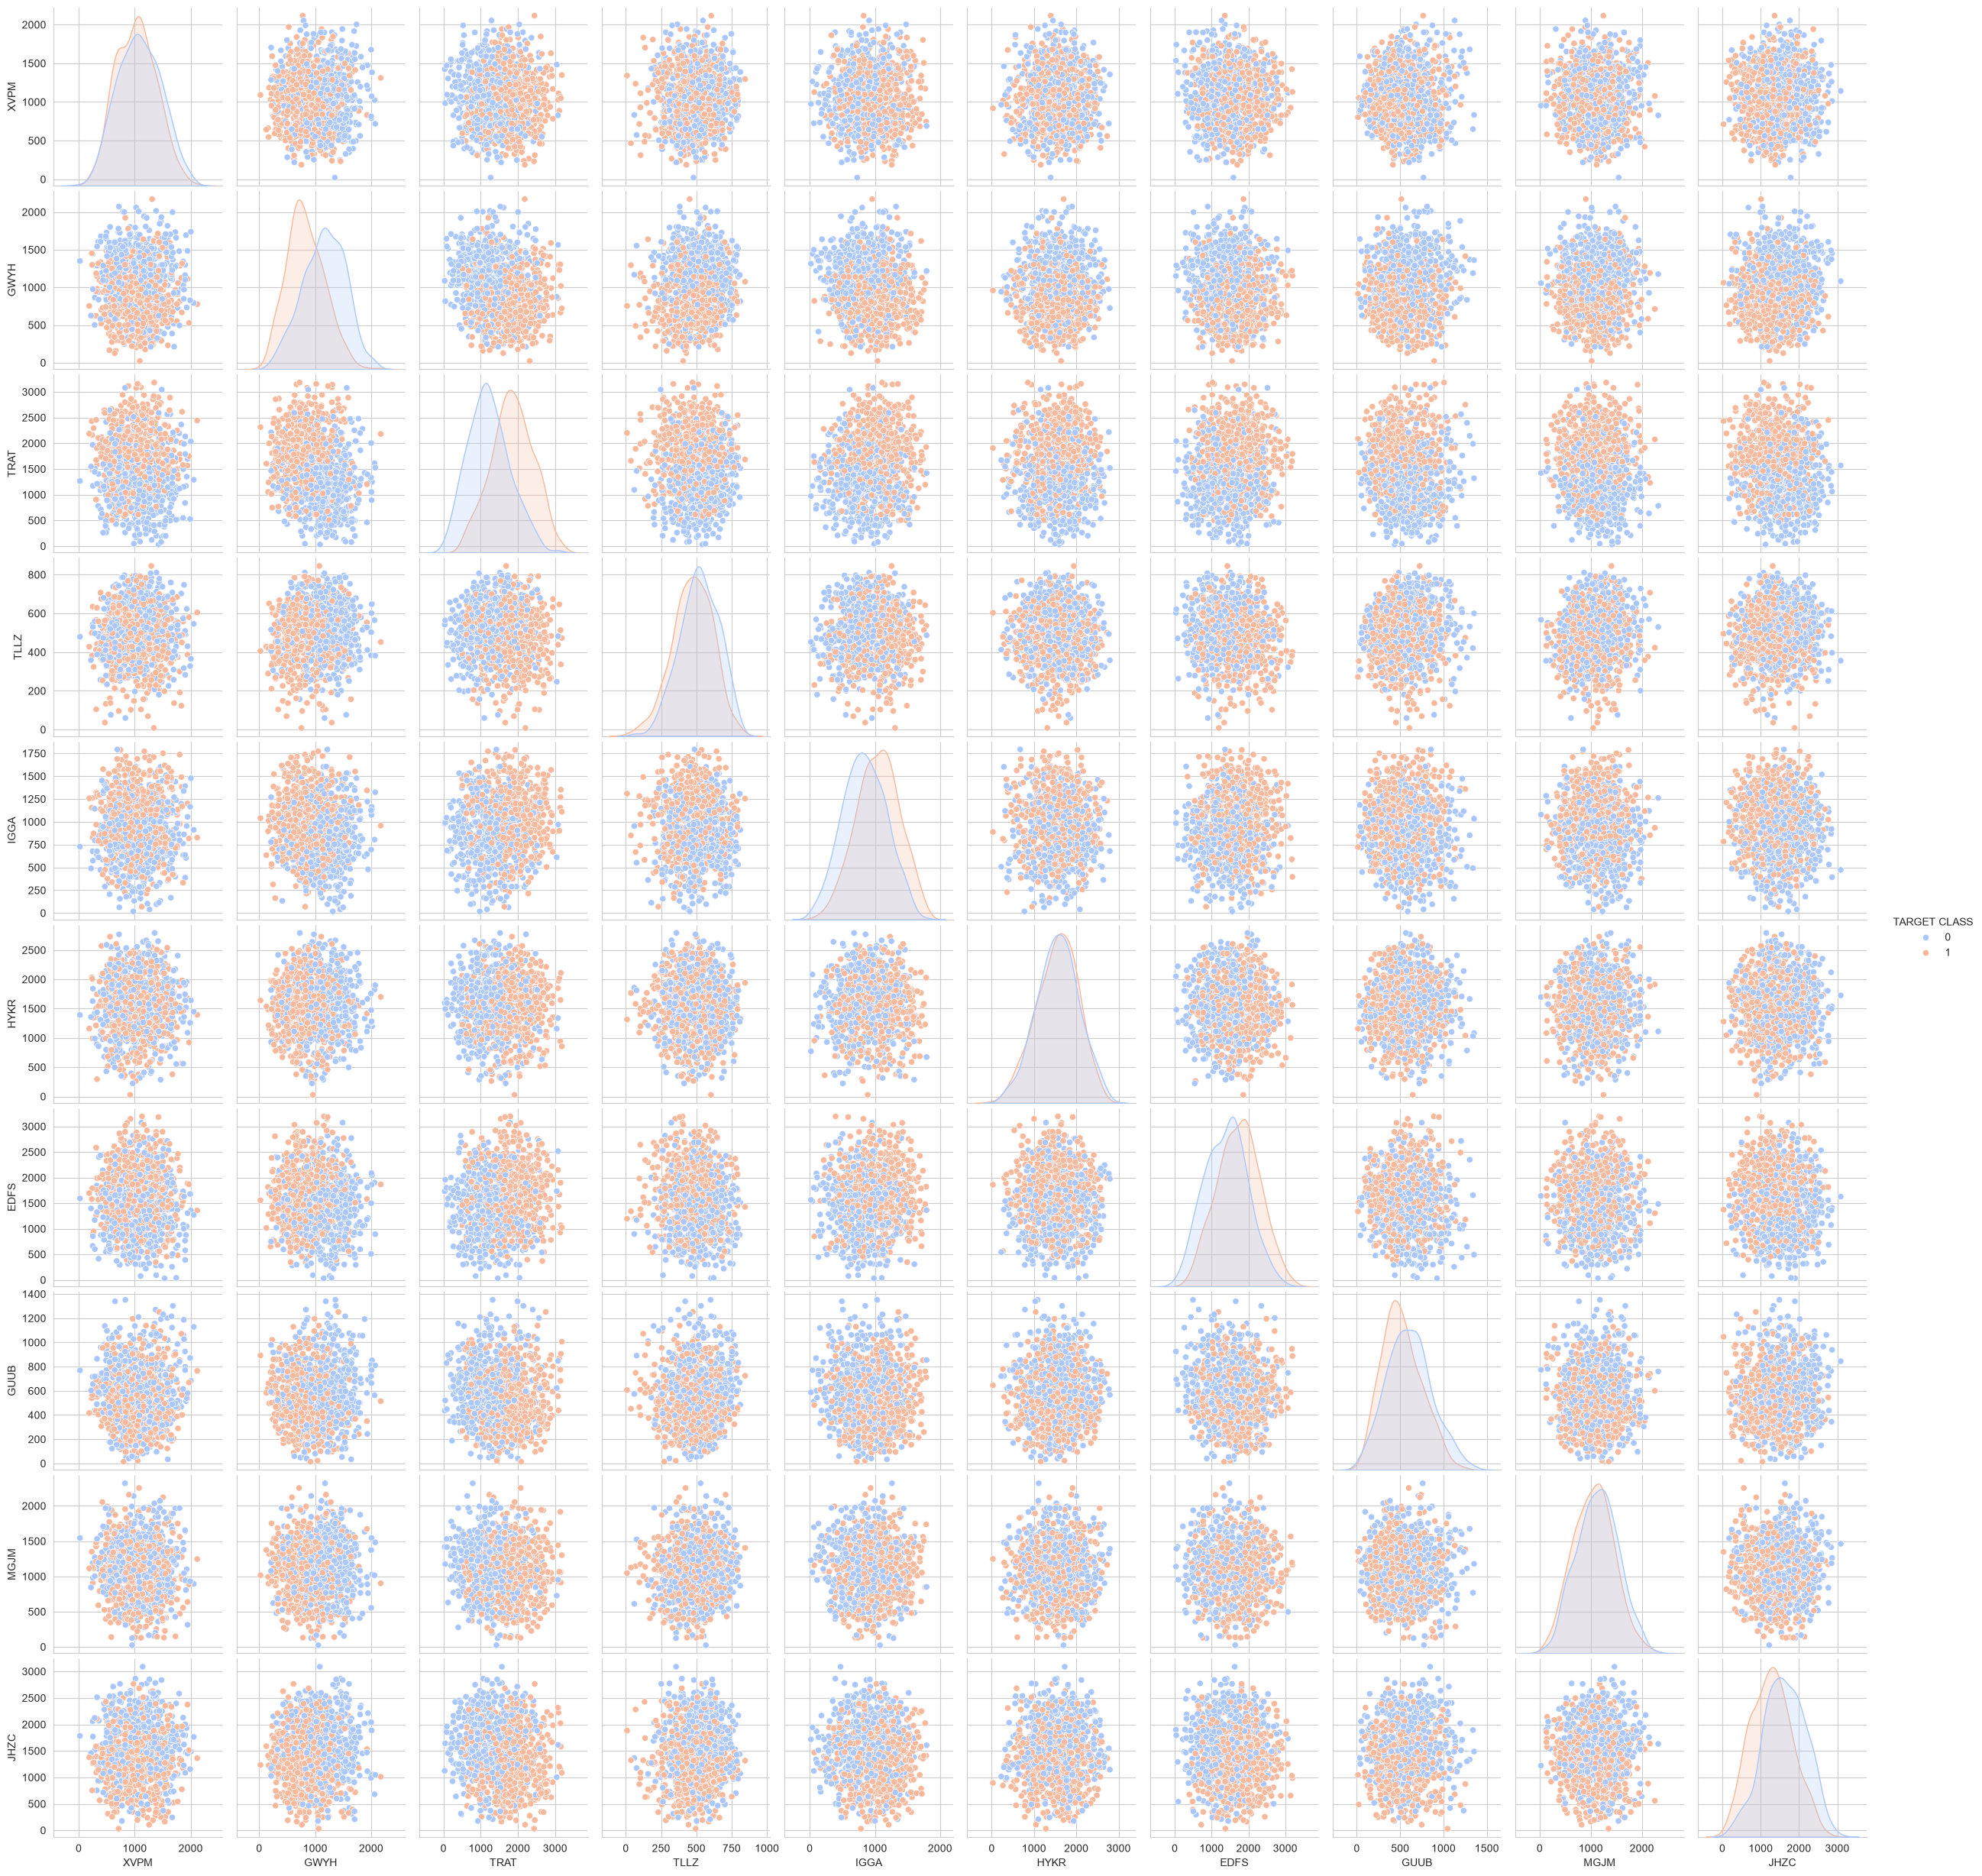

In [3]:
sns.pairplot(data=df, hue='TARGET CLASS', palette='coolwarm')

## 2. Standardising the features

KNN is distance-based, so features with large values would dominate the distance. All features are scaled to mean 0 and standard deviation 1.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df.drop('TARGET CLASS', axis=1))
scaled_features = scaler.transform(df.drop('TARGET CLASS', axis=1))

df_feat = pd.DataFrame(scaled_features, columns=df.columns[:-1])
df_feat.head()

,XVPM,GWYH,TRAT,TLLZ,IGGA,HYKR,EDFS,GUUB,MGJM,JHZC
0,1.568522,-0.443435,1.619808,-0.958255,-1.128481,0.138336,0.980493,-0.932794,1.008313,-1.069627
1,-0.112376,-1.056574,1.741918,-1.504220,0.640009,1.081552,-1.182663,-0.461864,0.258321,-1.041546
2,0.660647,-0.436981,0.775793,0.213394,-0.053171,2.030872,-1.240707,1.149298,2.184784,0.342811
3,0.011533,0.191324,-1.433473,-0.100053,-1.507223,-1.753632,-1.183561,-0.888557,0.162310,-0.002793
4,-0.099059,0.820815,-0.904346,1.609015,-0.282065,-0.365099,-1.095644,0.391419,-1.365603,0.787762


## 3. Train / test split

In [5]:
from sklearn.model_selection import train_test_split

X = df_feat
y = df['TARGET CLASS']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

## 4. Baseline: K = 1

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred))

[[109  43]
 [ 41 107]]

              precision    recall  f1-score   support

           0       0.73      0.72      0.72       152
           1       0.71      0.72      0.72       148

    accuracy                           0.72       300
   macro avg       0.72      0.72      0.72       300
weighted avg       0.72      0.72      0.72       300



## 5. Choosing K (elbow method)

I train a model for every K from 1 to 39 and record the test error rate.

In [7]:
error_rate = []

for i in range(1, 40):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error Rate')

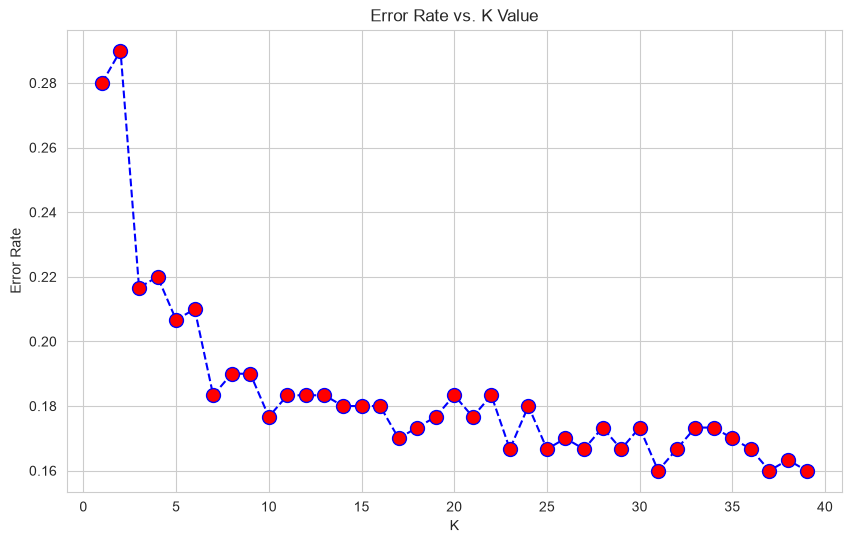

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 40), error_rate, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

## 6. Retraining with the chosen K

In [9]:
best_k = int(np.argmin(error_rate)) + 1
print('K with the lowest error rate:', best_k)

K with the lowest error rate: 31


In [10]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

print(f'WITH K={best_k}')
print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred))

WITH K=31
[[123  29]
 [ 19 129]]

              precision    recall  f1-score   support

           0       0.87      0.81      0.84       152
           1       0.82      0.87      0.84       148

    accuracy                           0.84       300
   macro avg       0.84      0.84      0.84       300
weighted avg       0.84      0.84      0.84       300



## 7. Conclusion

| Model | Accuracy |
|---|---|
| KNN, K = 1 | 0.72 |
| KNN, K = 31 | **0.84** |

- With K = 1 the model follows individual noisy points (high variance); accuracy is only 72%.
- The error rate drops quickly up to K ≈ 10 and then flattens around 16-18%. Larger K gives a smoother decision boundary.
- Choosing K = 31 raises accuracy from **72% to 84%**.

**Limitation:** K was chosen using the test set, which makes the final test score slightly optimistic.
A cleaner approach is to choose K with cross-validation on the training set (`GridSearchCV`) and use the test set only once at the end.